In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

columns = ["Sex", "Equipment", "Age", "BodyweightKg","WeightClassKg", 
"Division","Best3SquatKg", "Best3BenchKg", 
"Best3DeadliftKg", "TotalKg"]

# I've used  OpenPowerlifting -
# Open archive of the world's powerlifting competition results
# dataset from sports section from the Awesome Public Datasets
df = pd.read_csv("openpowerlifting.csv", usecols = columns, low_memory=False)

print("Rows and columns:", df.shape)
display(df.head())


Rows and columns: (4046314, 10)


,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,Best3SquatKg,Best3BenchKg,Best3DeadliftKg,TotalKg
0,F,Raw,28.5,Open,67.3,NaN,NaN,NaN,NaN,NaN
1,F,Raw,43.5,Open,73.2,NaN,NaN,90.0,NaN,90.0
2,F,Raw,26.5,Open,60.6,NaN,NaN,45.0,NaN,45.0
3,F,Raw,19.5,Juniors 17-21,50.3,NaN,NaN,35.0,NaN,35.0
4,F,Raw,19.5,Juniors 17-21,63.7,NaN,NaN,42.5,NaN,42.5


In [42]:
numeric_cols = ["Age", "BodyweightKg", "Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg", "TotalKg"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors = "coerce")

lift_cols = ["Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg"]

#Treat negative best-lift values as missing because they 
#indicate failed attempts.
for col in lift_cols:
    df[col] = df[col].where(df[col] > 0)

summary = df[numeric_cols].agg(["min", "max", "mean", "median"]).T

#Using the iqr method to calculate the outliers
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3-q1

    upper_bound = q3 + 1.5 * iqr
    lower_bound = q1 - 1.5 * iqr

    summary.loc[col, "outlier_count"] =(
        ((df[col] > upper_bound) | (df[col] < lower_bound)).sum()
    )
display(summary)
    
    





,min,max,mean,median,outlier_count
Age,0.0,105.5,30.681300,27.00,60768.0
BodyweightKg,15.0,300.0,83.765735,81.60,44505.0
Best3SquatKg,1.0,595.0,171.489628,165.56,20771.0
Best3BenchKg,1.0,659.0,114.904841,111.13,32142.0
Best3DeadliftKg,1.0,492.5,186.853021,185.00,2470.0
TotalKg,1.0,1407.5,379.880819,360.00,4108.0


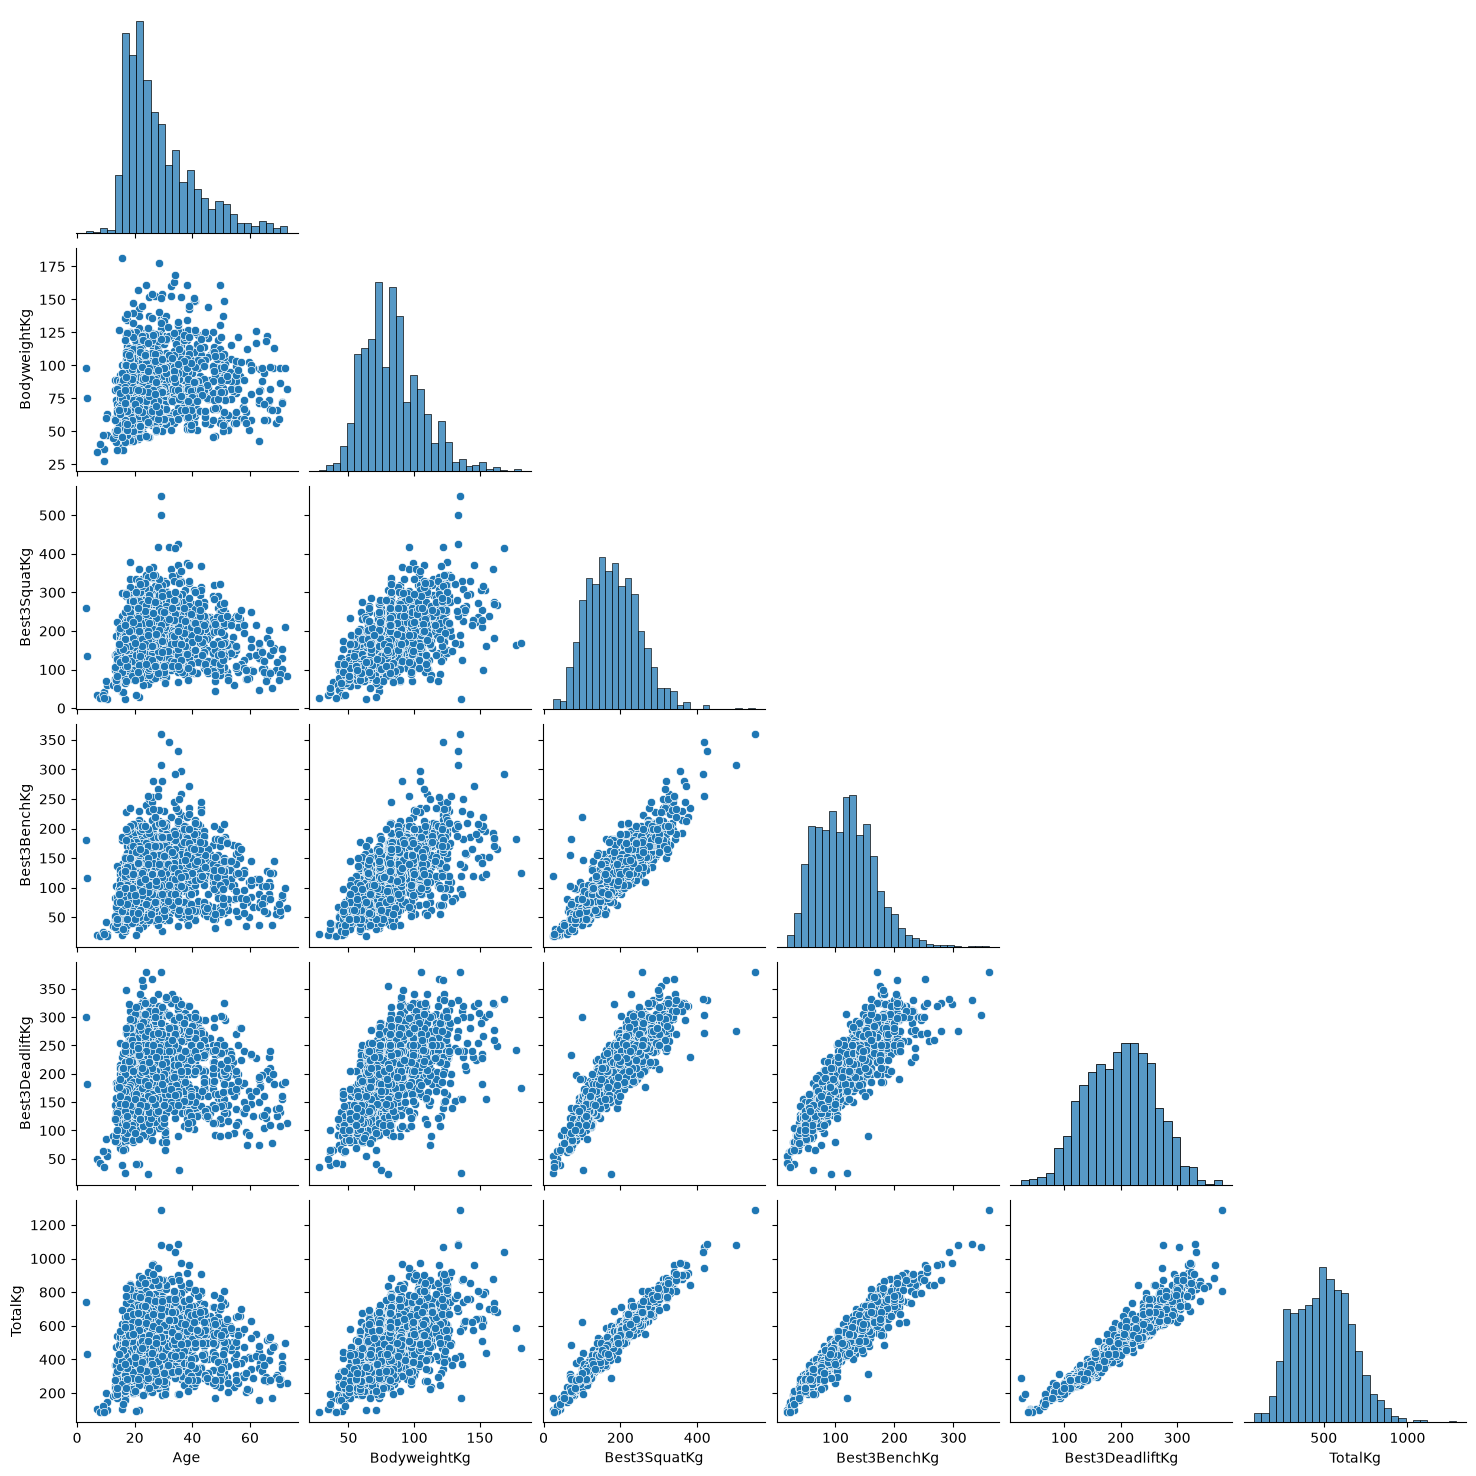

In [43]:
numeric_cols = ["Age", "BodyweightKg", "Best3SquatKg", 
                "Best3BenchKg", "Best3DeadliftKg", "TotalKg"]
plot_df = df[numeric_cols].apply(pd.to_numeric, errors = "coerce").dropna()
plot_sample= plot_df.sample(n=min(1500, len(plot_df)), random_state=42)
sns.pairplot(plot_sample, corner=True, diag_kind="hist")
plt.show()

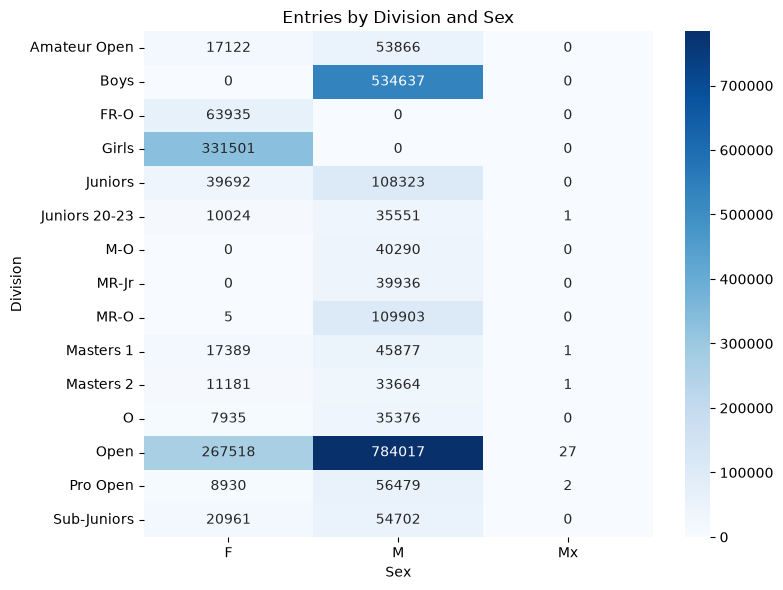

Male entries in Open: 784017


In [ ]:
# Compared categorical to categorical data by classifying 
# how many males are from open division
division_totals = df["Division"].value_counts()
selected_divisions = division_totals.head(15).index.tolist()


if "Open" in division_totals.index and "Open" not in selected_divisions:
    selected_divisions.append("Open")


filtered_df = df[df["Division"].isin(selected_divisions)]


division_sex_counts = pd.crosstab(
    filtered_df["Division"],
    filtered_df["Sex"]
)

#draw the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    division_sex_counts,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Entries by Division and Sex")
plt.xlabel("Sex")
plt.ylabel("Division")
plt.tight_layout()
plt.show()

# Prints the number of male entries in the Open division
if "Open" in division_sex_counts.index and "M" in division_sex_counts.columns:
    print(
        "Male entries in Open:",
        division_sex_counts.loc["Open", "M"]
    )
else:
    print("Check the division and sex labels in the heatmap.")

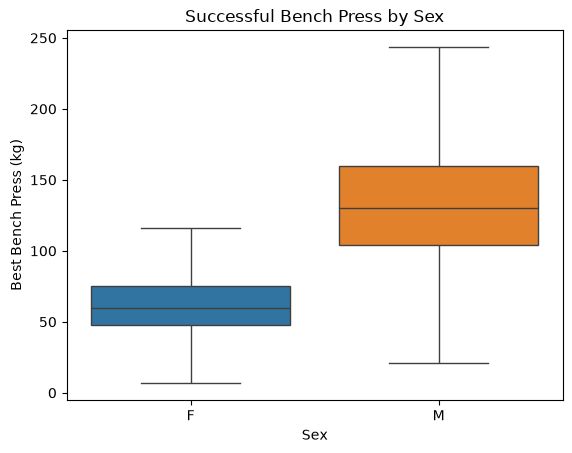

In [45]:
# Comparing categorical to numerical data by comparing sex 
# with best bench press
bench_data = df.loc[
    df["Sex"].isin(["M", "F"]),
    ["Sex", "Best3BenchKg"]
].dropna()

# Keep successful bench results only
bench_data = bench_data[bench_data["Best3BenchKg"] > 0]

# Compare the bench-weight distributions
sns.boxplot(
    data=bench_data,
    x="Sex",
    y="Best3BenchKg",
    hue="Sex",
    legend=False,
    showfliers=False
)

plt.title("Successful Bench Press by Sex")
plt.xlabel("Sex")
plt.ylabel("Best Bench Press (kg)")
plt.show()